In [104]:
import numpy as np
import pandas as pd

df = pd.read_csv("f1_pilot_puan_durumu.csv")
df = df[df["year"] >= 2008].reset_index(drop=True)
df

,driverStandingsId,raceId,driverId,points,position,positionText,wins,forename,surname,nationality,number,year,round,name
0,1,18,1,10.0,1,1,1,Lewis,Hamilton,British,44.0,2008,1,Australian Grand Prix
1,2,18,2,8.0,2,2,0,Nick,Heidfeld,German,NaN,2008,1,Australian Grand Prix
2,3,18,3,6.0,3,3,0,Nico,Rosberg,German,6.0,2008,1,Australian Grand Prix
3,4,18,4,5.0,4,4,0,Fernando,Alonso,Spanish,14.0,2008,1,Australian Grand Prix
4,5,18,5,4.0,5,5,0,Heikki,Kovalainen,Finnish,NaN,2008,1,Australian Grand Prix
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7483,73266,1144,858,0.0,23,23,0,Logan,Sargeant,American,2.0,2024,24,Abu Dhabi Grand Prix
7484,73267,1144,860,7.0,18,18,0,Oliver,Bearman,British,38.0,2024,24,Abu Dhabi Grand Prix
7485,73268,1144,861,5.0,19,19,0,Franco,Colapinto,Argentinian,43.0,2024,24,Abu Dhabi Grand Prix
7486,73269,1144,859,4.0,21,21,0,Liam,Lawson,New Zealander,30.0,2024,24,Abu Dhabi Grand Prix


In [105]:
print("İLK 5 SATIR")
display(df.head(5))

İLK 5 SATIR


,driverStandingsId,raceId,driverId,points,position,positionText,wins,forename,surname,nationality,number,year,round,name
0,1,18,1,10.0,1,1,1,Lewis,Hamilton,British,44.0,2008,1,Australian Grand Prix
1,2,18,2,8.0,2,2,0,Nick,Heidfeld,German,NaN,2008,1,Australian Grand Prix
2,3,18,3,6.0,3,3,0,Nico,Rosberg,German,6.0,2008,1,Australian Grand Prix
3,4,18,4,5.0,4,4,0,Fernando,Alonso,Spanish,14.0,2008,1,Australian Grand Prix
4,5,18,5,4.0,5,5,0,Heikki,Kovalainen,Finnish,NaN,2008,1,Australian Grand Prix


In [106]:
df.shape

(7488, 14)

In [107]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7488 entries, 0 to 7487
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  7488 non-null   int64  
 1   raceId             7488 non-null   int64  
 2   driverId           7488 non-null   int64  
 3   points             7488 non-null   float64
 4   position           7488 non-null   int64  
 5   positionText       7488 non-null   str    
 6   wins               7488 non-null   int64  
 7   forename           7488 non-null   str    
 8   surname            7488 non-null   str    
 9   nationality        7488 non-null   str    
 10  number             6251 non-null   float64
 11  year               7488 non-null   int64  
 12  round              7488 non-null   int64  
 13  name               7488 non-null   str    
dtypes: float64(2), int64(7), str(5)
memory usage: 819.1 KB


In [108]:
puanlar = np.array(df["points"])
galibiyetler = np.array(df["wins"])
print("-"*90)
print("Boyut:", puanlar.ndim)
print("Şekil:", puanlar.shape)
print("Eleman Sayısı:", puanlar.size)
print("Veri Tipi:", puanlar.dtype)
print("-"*90)
print("İlk 5 Puan:", puanlar[:5])
print("Son Puan:", puanlar[-1])
print("-"*90)
yuksek_puanlar = puanlar[puanlar >= 100]
orta_puanlar = puanlar[(puanlar >= 10) & (puanlar <= 100)]
print("100+ Puan Sayısı:", yuksek_puanlar.size)
print("10-100 Arası Puan Sayısı:", orta_puanlar.size)
print("-"*90)
print("Toplam Puan:", np.sum(puanlar))
print("Ortalama Puan:", np.mean(puanlar))
print("Medyan Puan:", np.median(puanlar))
print("Min Puan:", np.min(puanlar))
print("Max Puan:", np.max(puanlar))
print("Standart Sapma:", np.std(puanlar))
print("Toplam Galibiyet:", np.sum(galibiyetler))

------------------------------------------------------------------------------------------
Boyut: 1
Şekil: (7488,)
Eleman Sayısı: 7488
Veri Tipi: float64
------------------------------------------------------------------------------------------
İlk 5 Puan: [10.  8.  6.  5.  4.]
Son Puan: 0.0
------------------------------------------------------------------------------------------
100+ Puan Sayısı: 1193
10-100 Arası Puan Sayısı: 3118
------------------------------------------------------------------------------------------
Toplam Puan: 349715.5
Ortalama Puan: 46.70345886752137
Medyan Puan: 16.0
Min Puan: 0.0
Max Puan: 575.0
Standart Sapma: 71.65517086953174
Toplam Galibiyet: 3599


In [109]:
print(df.tail())
print(df.columns)
print(df[["forename", "surname", "year", "points", "wins"]].head())
print("-"*90)
britanyali_yuksek = df[(df["nationality"] == "British") & (df["points"] >= 300)]
rekor_kayitlar = df[(df["wins"] >= 15) | (df["points"] >= 500)]
print("Britanyalı ve 300+ Puanlı Kayıt:", len(britanyali_yuksek))
print("15+ Galibiyet veya 500+ Puanlı Kayıt:", len(rekor_kayitlar))
print("-"*90)
df["pilot_adi"] = df["forename"] + " " + df["surname"]
df["galibiyet_var_mi"] = df["wins"] > 0
df["yaris_basina_puan"] = df["points"] / df["round"]
print(df[["pilot_adi", "year", "points", "wins", "galibiyet_var_mi", "yaris_basina_puan"]].head())

      driverStandingsId  raceId  driverId  points  position positionText  \
7483              73266    1144       858     0.0        23           23   
7484              73267    1144       860     7.0        18           18   
7485              73268    1144       861     5.0        19           19   
7486              73269    1144       859     4.0        21           21   
7487              73270    1144       862     0.0        24           24   

      wins forename    surname    nationality  number  year  round  \
7483     0    Logan   Sargeant       American     2.0  2024     24   
7484     0   Oliver    Bearman        British    38.0  2024     24   
7485     0   Franco  Colapinto   Argentinian     43.0  2024     24   
7486     0     Liam     Lawson  New Zealander    30.0  2024     24   
7487     0     Jack     Doohan     Australian    61.0  2024     24   

                      name  
7483  Abu Dhabi Grand Prix  
7484  Abu Dhabi Grand Prix  
7485  Abu Dhabi Grand Prix  
7486  

In [110]:
print("En Çok Kaydı Bulunan İlk 5 Milliyet: ")
print(df["nationality"].value_counts(ascending=False).head(5))
print("-"*90)
print("En Çok Kaydı Bulunan İlk 5 Milliyet (Yüzde %): ")
print((df["nationality"].value_counts(normalize=True) * 100).head(5))
print("-"*90)
print("En Fazla Yarış Kaydı Olan İlk 5 Pilot: ")
print(df["pilot_adi"].value_counts().head(5))

En Çok Kaydı Bulunan İlk 5 Milliyet: 
nationality
German     1128
British    1005
French      666
Spanish     626
Finnish     575
Name: count, dtype: int64
------------------------------------------------------------------------------------------
En Çok Kaydı Bulunan İlk 5 Milliyet (Yüzde %): 
nationality
German     15.064103
British    13.421474
French      8.894231
Spanish     8.360043
Finnish     7.678953
Name: proportion, dtype: float64
------------------------------------------------------------------------------------------
En Fazla Yarış Kaydı Olan İlk 5 Pilot: 
pilot_adi
Lewis Hamilton      339
Fernando Alonso     301
Sebastian Vettel    288
Sergio Pérez        285
Daniel Ricciardo    268
Name: count, dtype: int64


In [111]:
en_yuksek_puan_5 = df.sort_values(by="points", ascending=False).head(5)
print(f'En Yüksek Puanlı İlk 5 Kayıt: {en_yuksek_puan_5[["pilot_adi", "year", "round", "name", "points", "wins"]]}')
print("-"*90)
coklu_sirali_5 = df.sort_values(by=["wins", "points"], ascending=[False, False]).head(5)
print(f'Galibiyet ve Puana Göre Çoklu Sıralama (İlk 5): {coklu_sirali_5[["pilot_adi", "year", "round", "wins", "points"]]}')

En Yüksek Puanlı İlk 5 Kayıt:            pilot_adi  year  round                      name  points  wins
6947  Max Verstappen  2023     22      Abu Dhabi Grand Prix   575.0    19
6945  Max Verstappen  2023     21      Las Vegas Grand Prix   549.0    18
6903  Max Verstappen  2023     20      São Paulo Grand Prix   524.0    17
6881  Max Verstappen  2023     19    Mexico City Grand Prix   491.0    16
6878  Max Verstappen  2023     18  United States Grand Prix   466.0    15
------------------------------------------------------------------------------------------
Galibiyet ve Puana Göre Çoklu Sıralama (İlk 5):            pilot_adi  year  round  wins  points
6947  Max Verstappen  2023     22    19   575.0
6945  Max Verstappen  2023     21    18   549.0
6903  Max Verstappen  2023     20    17   524.0
6881  Max Verstappen  2023     19    16   491.0
6878  Max Verstappen  2023     18    15   466.0


In [112]:
df.groupby("nationality")["points"].mean().sort_values(ascending=False).head(5)

nationality
Dutch         127.873541
Monegasque    107.543624
British        80.217413
Australian     65.539906
Finnish        61.780870
Name: points, dtype: float64

In [113]:
df.groupby("pilot_adi")["points"].agg(["count", "sum", "mean", "max"]).sort_values(by="max", ascending=False).reset_index()

,pilot_adi,count,sum,mean,max
0,Max Verstappen,209,32849.5,157.174641,575.0
1,Lewis Hamilton,339,50057.5,147.662242,413.0
2,Sebastian Vettel,288,32005.0,111.128472,397.0
3,Nico Rosberg,171,16712.0,97.730994,385.0
4,Lando Norris,128,11305.0,88.320312,374.0
...,...,...,...,...,...
83,Nikita Mazepin,22,0.0,0.000000,0.0
84,Roberto Merhi,18,0.0,0.000000,0.0
85,Sakon Yamamoto,10,0.0,0.000000,0.0
86,Takuma Sato,17,0.0,0.000000,0.0


Toplam 88 pilotun yer aldığı tabloya göre en yüksek tek sezon puanında (575.0) ve kayıt başına ortalamada (157.17) Max Verstappen ilk sırada bulunmaktadır. 
-------------------------------------------------------------------------------------------------------------------------------------------------
Toplam puanda (50057.5) ve kayıt sayısında (339) Lewis Hamilton liderdir.

In [114]:
print(f"Eksik Değerler: {df.isnull().sum()}")
print(f"Tekrarlayan Satır Sayısı: {df.duplicated().sum()}")

Eksik Değerler: driverStandingsId       0
raceId                  0
driverId                0
points                  0
position                0
positionText            0
wins                    0
forename                0
surname                 0
nationality             0
number               1237
year                    0
round                   0
name                    0
pilot_adi               0
galibiyet_var_mi        0
yaris_basina_puan       0
dtype: int64
Tekrarlayan Satır Sayısı: 0


In [115]:
df["number"] = df["number"].astype("Int64").astype("string").fillna("Numarası Yok")
df = df.drop_duplicates().reset_index(drop=True)
df.head(5)

,driverStandingsId,raceId,driverId,points,position,positionText,wins,forename,surname,nationality,number,year,round,name,pilot_adi,galibiyet_var_mi,yaris_basina_puan
0,1,18,1,10.0,1,1,1,Lewis,Hamilton,British,44,2008,1,Australian Grand Prix,Lewis Hamilton,True,10.0
1,2,18,2,8.0,2,2,0,Nick,Heidfeld,German,Numarası Yok,2008,1,Australian Grand Prix,Nick Heidfeld,False,8.0
2,3,18,3,6.0,3,3,0,Nico,Rosberg,German,6,2008,1,Australian Grand Prix,Nico Rosberg,False,6.0
3,4,18,4,5.0,4,4,0,Fernando,Alonso,Spanish,14,2008,1,Australian Grand Prix,Fernando Alonso,False,5.0
4,5,18,5,4.0,5,5,0,Heikki,Kovalainen,Finnish,Numarası Yok,2008,1,Australian Grand Prix,Heikki Kovalainen,False,4.0


Yapılan kontrolde tekrarlayan kayıt bulunmadı ("0"), yalnızca "number" sütununda tespit edilen "1.237" adet eksik değer "Numarası Yok" etiketiyle doldurulmuştur. Temizlik öncesi "7.488" olan satır sayısı veri kaybı yaşanmadan korunmuştur.

In [116]:
print(f"Temizlik Sonrası Boyut: {df.shape}")
print("-"*90)
print(f'Kalan Eksik Değerler: {df.isnull().sum()}')
print("-"*90)
print(f"Kalan Tekrarlayan Satır Sayısı: {df.duplicated().sum()}")

Temizlik Sonrası Boyut: (7488, 17)
------------------------------------------------------------------------------------------
Kalan Eksik Değerler: driverStandingsId    0
raceId               0
driverId             0
points               0
position             0
positionText         0
wins                 0
forename             0
surname              0
nationality          0
number               0
year                 0
round                0
name                 0
pilot_adi            0
galibiyet_var_mi     0
yaris_basina_puan    0
dtype: int64
------------------------------------------------------------------------------------------
Kalan Tekrarlayan Satır Sayısı: 0


In [117]:
df.describe()

,driverStandingsId,raceId,driverId,points,position,wins,year,round,yaris_basina_puan
count,7488.000000,7488.000000,7488.000000,7488.000000,7488.000000,7488.000000,7488.000000,7488.000000,7488.000000
mean,62516.788061,852.119525,491.225427,46.703459,11.614450,0.480636,2016.143162,10.776042,4.358124
std,18084.589141,327.760152,398.052784,71.659956,6.524838,1.522775,4.909880,5.889429,5.587752
min,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,2008.000000,1.000000,0.000000
25%,65089.750000,866.000000,16.000000,1.000000,6.000000,0.000000,2012.000000,6.000000,0.125000
50%,67888.500000,960.000000,815.000000,16.000000,12.000000,0.000000,2016.000000,11.000000,1.844130
75%,70296.250000,1052.000000,832.000000,57.000000,17.000000,0.000000,2021.000000,16.000000,6.950110
max,73270.000000,1144.000000,862.000000,575.000000,28.000000,19.000000,2024.000000,24.000000,26.200000


In [118]:
print(f"Kalan Eksik Değerler: {df.isnull().sum()}")
print("-"*90)
print(f"Temizlik Sonrası Boyut: {df.shape}")
print("-"*90)
print(f"Kalan Tekrarlayan Satır Sayısı: {df.duplicated().sum()}")

Kalan Eksik Değerler: driverStandingsId    0
raceId               0
driverId             0
points               0
position             0
positionText         0
wins                 0
forename             0
surname              0
nationality          0
number               0
year                 0
round                0
name                 0
pilot_adi            0
galibiyet_var_mi     0
yaris_basina_puan    0
dtype: int64
------------------------------------------------------------------------------------------
Temizlik Sonrası Boyut: (7488, 17)
------------------------------------------------------------------------------------------
Kalan Tekrarlayan Satır Sayısı: 0


Bu veri setinde veri kaybını önlemek ve bütünlüğü korumak amacıyla "number" sütunundaki "1.237" adet eksik değeri "Numarası Yok" etiketiyle doldurdum, tekrar kontrolünde ("0") kopya kayıt bulunmadığını doğruladım. "df.describe()" ile yapılan sınır ve aykırı değer kontrolünde negatif veya imkansız bir kayıt tespit edilmemiş; "575.0" puan ve "19" galibiyet gibi yüksek değerler gerçek yarış rekorlarını yansıttığı için silmeden korudum. Tüm temizlik adımları sonucunda başlangıçtaki "7.488" satır ve "17" sütunluk veri seti eksiksiz şekilde koruyarak görselleştirme aşamasına hazır hale getirdim.

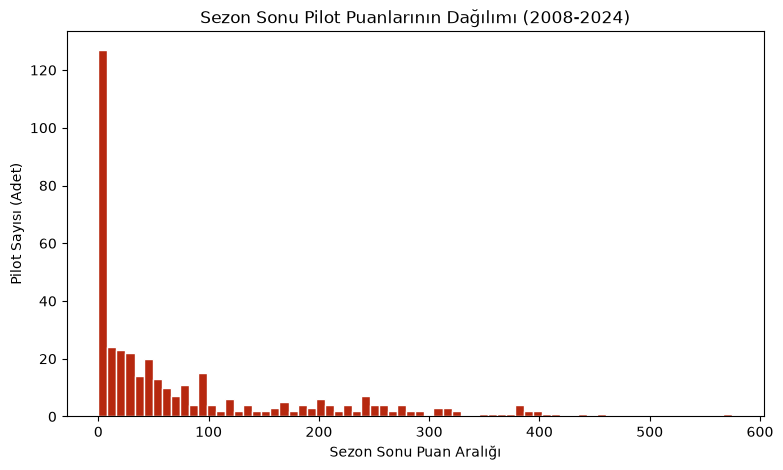

In [119]:
import matplotlib.pyplot as plt

sezon_sonu = df[df["round"] == df.groupby("year")["round"].transform("max")]
plt.figure(figsize=(9, 5))
plt.hist(sezon_sonu["points"], bins=70, color="#b6280f", edgecolor="white")
plt.title("Sezon Sonu Pilot Puanlarının Dağılımı (2008-2024)")
plt.xlabel("Sezon Sonu Puan Aralığı")
plt.ylabel("Pilot Sayısı (Adet)")
plt.show()

Sezon sonu puan dağılımını gösteren histogram grafiğine göre 2008–2024 dönemindeki pilotların büyük çoğunluğu **0 ile 50 puan** arasındaki ilk aralıkta yoğunlaşmış. Puan aralığı yükseldikçe pilot sayısının belirgin biçimde azalması, yüksek sezon sonu puanlarına yalnızca sınırlı sayıdaki zirve pilotunun ulaşabildiğini gösteriyor.

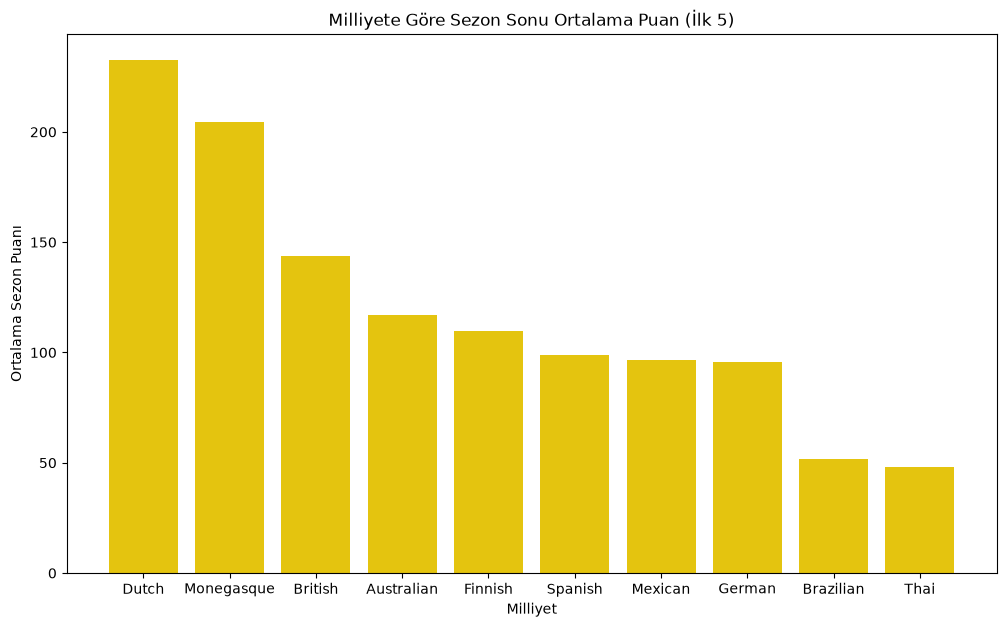

In [120]:
ozet_milliyet = sezon_sonu.groupby("nationality")["points"].mean().round(2).sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 7))
plt.bar(ozet_milliyet.index, ozet_milliyet.values, color="#e4c40f")
plt.title("Milliyete Göre Sezon Sonu Ortalama Puan (İlk 5)")
plt.xlabel("Milliyet")
plt.ylabel("Ortalama Sezon Puanı")
plt.show()

Sezon sonu ortalama puanları gösteren sütun grafiğine göre **Hollandalı pilotlar (200+ puan)** ilk sırada yer alırken, **Monakolu pilotlar (200+ puan)** ikinci sıradadır. İlk 5 milliyetin tamamı sezon başına **100 puan** ortalamasının üzerinde yer almaktadır.